# Function 1 — Week 7: signed score, log magnitude and raw magnitude

Compare three separately fitted targets using **16 official observations through round 6** and **six unchanged retained peer reports**. The latest official return is **2.1709129251221444e-14** at `(0.537942, 0.522217)`, received on 2 November 2026. This is the highest official signed score, while remaining practically zero; no source-detection threshold is established.

The purpose is to choose a defensible next experiment after testing the central-region hunch. The earlier signed GP/UCB proposal is a reference, not an agreed decision. Activity may suggest where to learn about stronger responses; its sign-free objective does not establish a positive return. Seven queries remain, including Week 7.

[Reading report](../activity-hypothesis.md) · [Week-level review](../report.md) · [Previous comparison](../../Week_06/activity-hypothesis.md)


## Comparison and decision boundary

Keep last week's four GP families, target scale, leave-one-out MAE selection, optimiser budget, exploration weights and search settings. Fit official-only and peer-assisted models on identical held-out official targets. All three targets receive the same candidates in each pool. A second, shared pool adds the strongest-response neighbourhood to check sensitivity to search coverage.

Inspect candidate location, validation against each target's own baseline, signed predictions at activity-led points, scope/model/weight sensitivity and movement from Week 6. Distance to the geometric centre is descriptive, not a selection criterion or distance to a known source. Save the recommendation after examining these results; no portal submission or new course evaluation is performed.


### Recommendation following the full comparison

Recommend **`0.340635-0.362578`**, the log-magnitude GP/UCB point at weight **1.96**, for **one activity-led exploration query**. It is recommended for discussion, without final agreement or submission. The original signed-policy candidate stays available as a comparator.

The log-magnitude GP improves on both its mean and median baselines, its selected point survives the shared-pool expansion unchanged, and weights 0–3 stay in the same lower-left neighbourhood. The raw-magnitude GP loses to its median baseline and its location is more sensitive to GP family and retained peers. Centre proximity is not the reason for the recommendation.

The signed model's mean at the recommended point is **-19.455 h**, with latent SD **139.400 h**. Its sign is unresolved and a negative return is a material possibility. This is a deliberate learning experiment, not a demonstrated predicted improvement or source detection.


In [1]:
%matplotlib inline
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "1"
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

root = next(p for p in Path.cwd().parents if (p / "run-python.ps1").is_file())
expected = root / ".venv/Scripts/python.exe"
if Path(sys.executable).resolve() != expected.resolve():
    raise RuntimeError(f"Select the capstone-local interpreter: {expected}")
shared = root / "stage-2-bbo/notebooks/Shared"
function_shared = shared.parent / "Function_1/FunctionSpecificShared"
for folder in (shared, function_shared):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from cohort_review_helpers import load_cohort_review
from function_1_activity_helpers import (
    TARGET_LABELS, activity_targets, fit_activity_targets, common_activity_pools,
    compare_activity_policies, opposite_sign_pairs, plot_activity_evidence,
    plot_activity_decisions, plot_activity_query_shift,
)
print("Python interpreter:", sys.executable)

from model_review_plots import plot_held_out_comparison
from query_budget import remaining_queries


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Declare the comparison before fitting; no tuning is based on whether a point is central.
FUNCTION = 1
WEEK = 7
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
OUTPUT_DIR = ANALYSIS_DIR / "activity-hypothesis"
DATA_PATH = ANALYSIS_DIR / "observations.csv"
COHORT_PATH = WEEK_DIR / "cohort/observations.csv"
AUDIT_PATH = WEEK_DIR / "cohort/data-audit.json"
MODEL_REVIEW_PATH = ANALYSIS_DIR / "model-review.json"
SUBMISSION_PATH = root / "stage-2-bbo/submissions/Week_06/submissions.txt"
INPUT_COLUMNS = ["x1", "x2"]
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1}
HEIGHT_SCALE = 1e-200
CENTRE = (.5, .5)  # Geometric reference, not an assumed source location.
FIXED_SETTINGS = dict(ridge_alpha=1., quadratic_degree=2, noise_fraction=.1,
    gp_length_scales={"GP: local (l=0.15)": .15, "GP: broad (l=0.35)": .35})
ADAPTIVE_SETTINGS = dict(noise_fraction=.1, optimiser_restarts=3, seed=42)
GP_NAMES = ["GP: local (l=0.15)", "GP: broad (l=0.35)", "Gaussian process", "GP: separate length scales"]
SELECTION_METRIC = "LOO MAE"
WEIGHT = 1.96
WEIGHTS = (0., 1., 1.96, 3.)
SEARCH_SETTINGS = dict(broad_power=14, broad_seed=42, local_power=12,
    local_seed=43, local_radius=.15, precision=6, include_corners=True)

STUDY_DATE = "2026-11-05"
PREVIOUS_STUDY_PATH = root / "stage-2-bbo/notebooks/Function_1/Week_06/official/activity-hypothesis/results.json"
SUBMISSION_PATHS = sorted((root / "stage-2-bbo/submissions").glob("Week_*/submissions.txt"))


## 1. Separate score from activity

The signed score remains the course objective. The existing transform preserves its ordering:

$$h(y)=\operatorname{sign}(y)\log_{10}(1+|y|/s),\qquad s=10^{-200}.$$

The activity target deliberately discards sign:

$$g(y)=\log_{10}(1+|y|/s)=|h(y)|.$$

A third fit uses **literal raw magnitude** $|y|$, checking whether a central pull depends on the logarithmic scale. Each target gets a separate complete fit; taking the absolute value of a signed model's fitted mean is a different operation and is not used here. Target errors and acquisition scores have different meanings and units, so they are compared with their own baselines only.


In [3]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
submission_before = {p.relative_to(root).as_posix(): sha(p) for p in SUBMISSION_PATHS}
saved = json.loads(MODEL_REVIEW_PATH.read_text(encoding="utf-8"))
audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
assert sha(DATA_PATH) == saved["snapshot_sha256"]
assert sha(COHORT_PATH) == audit["cohort_csv_sha256"]
assert sha(AUDIT_PATH) == saved["cohort_audit_sha256"]
review = load_cohort_review(COHORT_PATH, DATA_PATH, input_columns=INPUT_COLUMNS,
    expected_round_counts=EXPECTED_ROUND_COUNTS, expected_peer_count=6)
official, pooled = review["own_data"], review["data"]
reference = np.asarray(saved["point"])
OUTPUT_DIR.mkdir(exist_ok=True)
display(pd.DataFrame({"Snapshot": ["Official", "Official + retained peers"],
    "Rows": [len(official), len(pooled)],
    "Positive": [int((d.y>0).sum()) for d in (official,pooled)],
    "Negative": [int((d.y<0).sum()) for d in (official,pooled)],
    "Exactly zero": [int((d.y==0).sum()) for d in (official,pooled)]}))
targets = activity_targets(pooled.y.to_numpy(), scale=HEIGHT_SCALE)
measurements = pooled.assign(signed_h=targets["signed"], activity_g=targets["magnitude"],
    absolute_y=targets["raw_magnitude"], distance_to_centre=np.linalg.norm(pooled[INPUT_COLUMNS]-CENTRE,axis=1))
display(measurements.sort_values("absolute_y",ascending=False).head(8).style.format({
    "y":"{:.6e}", "absolute_y":"{:.6e}", "signed_h":"{:.3f}", "activity_g":"{:.3f}",
    "x1":"{:.6f}", "x2":"{:.6f}", "distance_to_centre":"{:.4f}"}))

assert len(official) == 16 and len(pooled) == 22
assert official.iloc[-1].observation_id == "round-06"
assert official.iloc[-1].y == 2.1709129251221444e-14
latest_mask = official.source_round.eq(6).to_numpy()
source_paths = [DATA_PATH, COHORT_PATH, AUDIT_PATH, MODEL_REVIEW_PATH, PREVIOUS_STUDY_PATH,
    function_shared / "function_1_activity_helpers.py", function_shared / "function_1_model_helpers.py",
    *[shared / f"{name}.py" for name in ("model_helpers", "model_review_helpers", "prediction_review_helpers",
                                      "surrogate_study_helpers", "cohort_review_helpers")]]
source_before = {p.relative_to(root).as_posix(): sha(p) for p in source_paths}
print(f"Seven query opportunities including Week 7: {remaining_queries(WEEK_DIR)}")


,Snapshot,Rows,Positive,Negative,Exactly zero
0,Official,16,9,7,0
1,Official + retained peers,22,10,12,0


,observation_id,source_round,x1,x2,y,signed_h,activity_g,absolute_y,distance_to_centre
16,peer-kosina-round-01,1,0.419675,0.463269,-6.137883e-03,-197.788,197.788,6.137883e-03,0.0883
10,round-01,1,0.468429,0.435440,-5.509346e-03,-197.741,197.741,5.509346e-03,0.0719
4,initial-005,0,0.650114,0.681526,-3.606063e-03,-197.557,197.557,3.606063e-03,0.2356
18,peer-tomxandrews-round-01,1,0.670114,0.666526,-3.606000e-03,-197.557,197.557,3.606000e-03,0.2381
19,peer-arwelbrown-round-02,2,0.584884,0.598963,-3.606000e-03,-197.557,197.557,3.606000e-03,0.1304
20,peer-kosina-round-02,2,0.540351,0.524565,1.180859e-13,187.072,187.072,1.180859e-13,0.0472
15,round-06,6,0.537942,0.522217,2.170913e-14,186.337,186.337,2.170913e-14,0.0440
2,initial-003,0,0.731024,0.733000,7.710875e-16,184.887,184.887,7.710875e-16,0.3281


Seven query opportunities including Week 7: 7


Every stored reading is numerically non-zero. A zero/non-zero detector cannot distinguish useful activity here, and no background or practical detection threshold is supplied. Larger negative magnitudes are retained as evidence about response strength. They are not assumed to be noise, and the existence of a nearby positive peak remains a hypothesis.

The six peer rows are self-reported, audited training evidence. They do not change the owner's 16 observations, incumbent or query budget. The pair table below describes nearby opposite signs without claiming an unseen source or a sign-change law.


,positive_id,negative_id,positive_output,negative_output,input_distance
0,initial-009,peer-tomxandrews-round-02,3.606771e-81,-1.434379e-124,0.08354
1,peer-kosina-round-02,peer-arwelbrown-round-02,1.180859e-13,-3.606000e-03,0.08671
2,round-06,peer-arwelbrown-round-02,2.170913e-14,-3.606000e-03,0.08996
3,initial-003,peer-tomxandrews-round-01,7.710875e-16,-3.606000e-03,0.09016
4,initial-003,initial-005,7.710875e-16,-3.606063e-03,0.09590
5,round-06,round-01,2.170913e-14,-5.509346e-03,0.11119


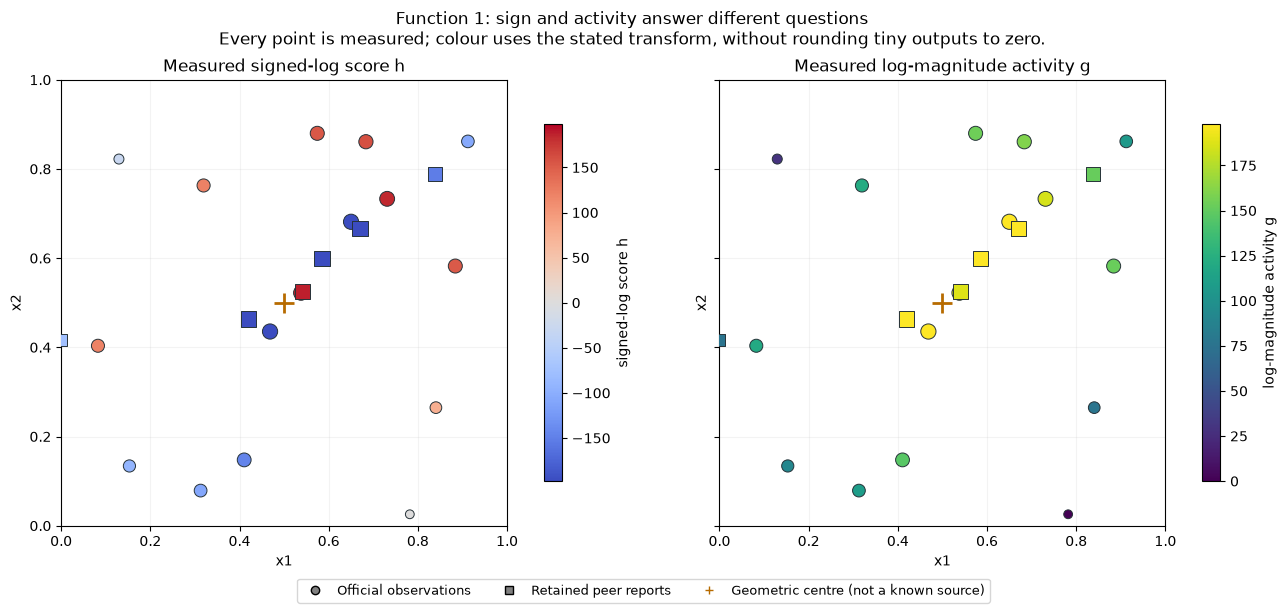

In [4]:
display(opposite_sign_pairs(pooled, input_columns=INPUT_COLUMNS).style.format({
    "positive_output":"{:.6e}", "negative_output":"{:.6e}", "input_distance":"{:.5f}"}))
display(plot_activity_evidence(pooled, scale=HEIGHT_SCALE, input_columns=INPUT_COLUMNS,
    save_to=OUTPUT_DIR / "measured-sign-and-activity.png"))


## 2. Hold validation and candidate construction fixed

Compare the four established GP families and retain **LOO MAE** selection within each target. Official-only and peer-assisted fits score the **same 16 held-out official rows**. Peer observations enter training only. No source repository is refreshed.

The baseline pool reproduces the saved Week 7 signed policy's seeded broad/incumbent-local construction. The symmetric pool supplies all three policies with the same additional neighbourhood around the strongest absolute response, the geometric centre and the provisional signed point. Exclude all known official and peer coordinates. Expansion is a declared sensitivity check, not tuning for a desired location.


In [5]:
study = fit_activity_targets(official, pooled, input_columns=INPUT_COLUMNS,
    scale=HEIGHT_SCALE, fixed_settings=FIXED_SETTINGS, adaptive_settings=ADAPTIVE_SETTINGS,
    gp_names=GP_NAMES, selection_metric=SELECTION_METRIC)
activity_anchor = pooled.loc[pooled.y.abs().idxmax(), INPUT_COLUMNS].to_numpy(float)
pools = common_activity_pools(official[INPUT_COLUMNS].to_numpy(), pooled[INPUT_COLUMNS].to_numpy(),
    official.y.to_numpy(), input_columns=INPUT_COLUMNS, search_settings=SEARCH_SETTINGS,
    prepared_point=reference, centre=CENTRE, activity_anchor=activity_anchor)
policies = compare_activity_policies(study, pools, input_columns=INPUT_COLUMNS,
    reference=reference, gp_names=GP_NAMES, weights=WEIGHTS, main_weight=WEIGHT, centre=CENTRE)
assert study["studies"]["signed"]["selected"]["name"] == saved["query_model"]
assert study["studies"]["signed"]["selected"]["scope"] == saved["training_scope"]
np.testing.assert_allclose(study["studies"]["signed"]["selected"]["error"], saved["official_target_error"], rtol=1e-10)
np.testing.assert_array_equal(policies["proposals"]["baseline"]["signed"]["point"], reference)
print("Reproduced the saved Week 7 signed-score GP, held-out error and provisional point.")


Target: signed-log score h


Regression complete: Mean baseline; warnings=0


Regression complete: GP: local (l=0.15); warnings=0


Regression complete: GP: broad (l=0.35); warnings=0


Regression complete: Gaussian process; warnings=17


Regression complete: GP: separate length scales; warnings=28

... (21 outputs left out)

Peer-assisted official-target review complete: GP: broad (l=0.35)


Peer-assisted official-target review complete: Gaussian process


Peer-assisted official-target review complete: GP: separate length scales


Reproduced the saved Week 7 signed-score GP, held-out error and provisional point.


,Target,Selected GP,Scope,Selected kernel,Official-target MAE,Own-target mean-baseline MAE,MAE / own baseline
0,signed-log score h,Gaussian process,official_plus_retained_peers,0.94**2 * RBF(length_scale=0.046),109.584157,135.523206,0.808601
1,log-magnitude activity g,Gaussian process,official_plus_retained_peers,1.71**2 * RBF(length_scale=0.327),16.952687,48.422875,0.350097
2,absolute raw output |y|,GP: separate length scales,official_plus_retained_peers,"0.901**2 * RBF(length_scale=[0.258, 0.0364])",0.000786,0.001063,0.738658


signed-log score h


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,GP: local (l=0.15),279.985362,184.825263,205.786113,143.091343,0
1,GP: broad (l=0.35),246.374169,210.051477,195.924267,183.097675,0
2,Gaussian process,147.135264,128.914152,135.651902,109.584157,0
3,GP: separate length scales,159.799443,131.604831,143.992843,111.391461,4


log-magnitude activity g


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,GP: local (l=0.15),42.067521,43.828328,26.631361,25.933368,0
1,GP: broad (l=0.35),29.174468,24.835482,21.556723,17.673279,0
2,Gaussian process,35.138313,26.525694,22.339317,16.952687,0
3,GP: separate length scales,36.628727,27.605205,24.989488,16.974698,0


absolute raw output |y|


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,GP: local (l=0.15),0.003105,0.001476,0.002197,0.001252,0
1,GP: broad (l=0.35),0.002644,0.002091,0.001949,0.001782,0
2,Gaussian process,0.001648,0.000963,0.001065,0.000881,0
3,GP: separate length scales,0.001673,0.000980,0.001100,0.000786,0


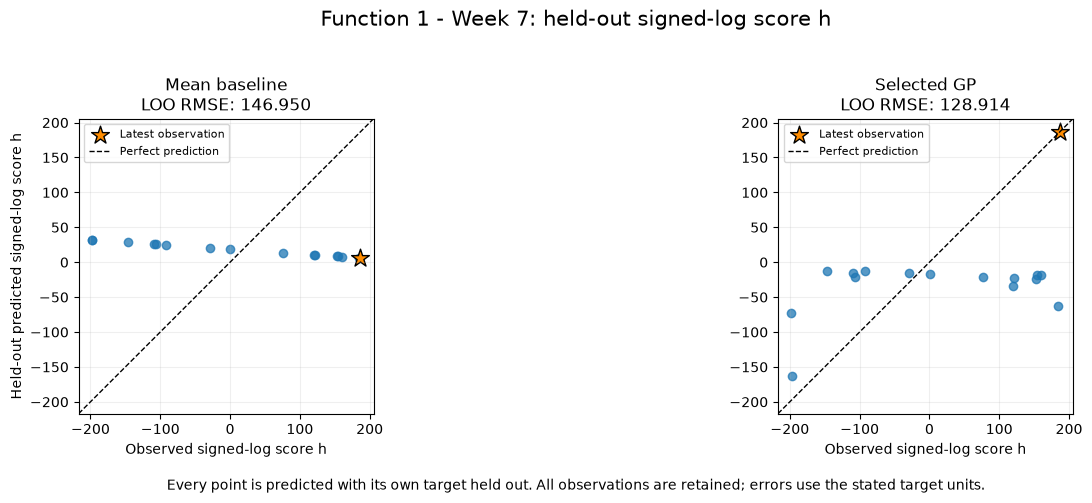

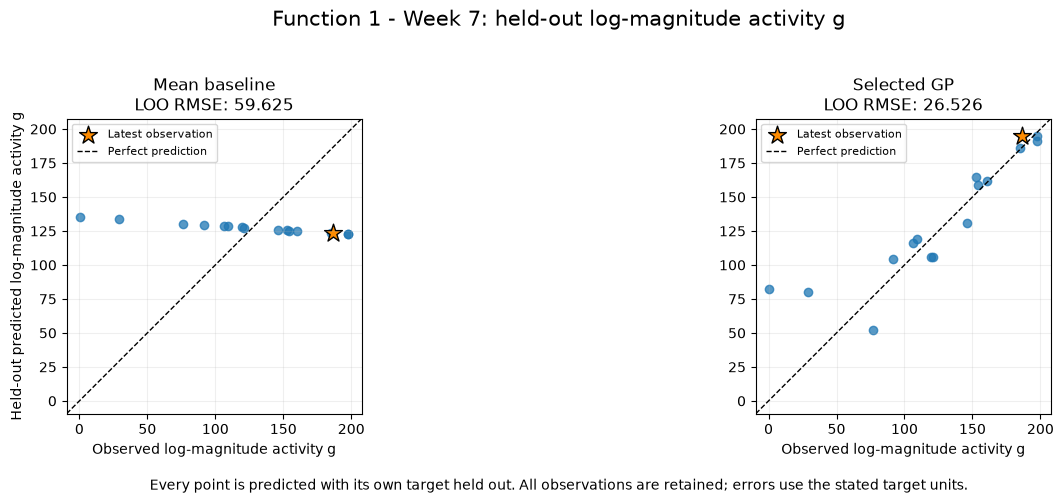

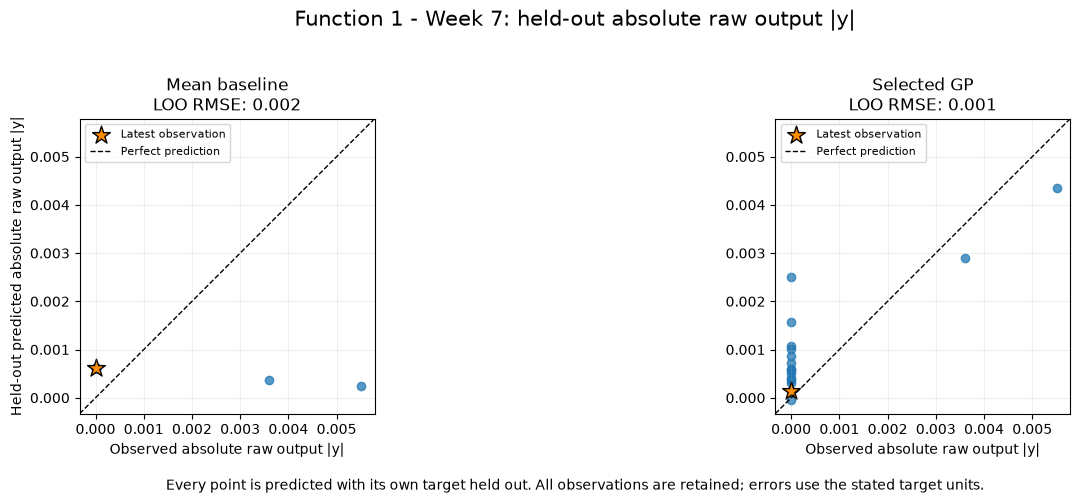

,target,units,median_baseline_mae,selected_gp_mae,gp_beats_median_baseline
0,signed,signed-log score h,165.078410,109.584157,True
1,magnitude,log-magnitude activity g,58.002869,16.952687,True
2,raw_magnitude,absolute raw output |y|,0.000570,0.000786,False


In [6]:
validation_rows = []
for name, run in study["studies"].items():
    selected = run["selected"]
    baseline = float(run["official"]["table"].set_index("Model").loc["Mean baseline", SELECTION_METRIC])
    validation_rows.append({"Target": TARGET_LABELS[name], "Selected GP": selected["name"],
        "Scope": selected["scope"], "Selected kernel": str(selected["model"].kernel_), "Official-target MAE": selected["error"],
        "Own-target mean-baseline MAE": baseline, "MAE / own baseline": selected["error"]/baseline})
display(pd.DataFrame(validation_rows))
for name, run in study["studies"].items():
    print(TARGET_LABELS[name])
    display(run["peers"]["table"])

# Compare each target against its own baseline; never rank unlike target units.
for name, run in study["studies"].items():
    selected = run["selected"]
    fitted_scope = run["official"] if selected["scope"] == "official" else run["peers"]
    predictions = {"Mean baseline": run["official"]["predictions"]["Mean baseline"],
                   "Selected GP": fitted_scope["predictions"][selected["name"]]}
    display(plot_held_out_comparison(predictions, run["target"],
        model_names=["Mean baseline", "Selected GP"], latest_mask=latest_mask,
        target_label=TARGET_LABELS[name], title=f"Function 1 - Week 7: held-out {TARGET_LABELS[name]}",
        save_to=OUTPUT_DIR / f"{name}-held-out.png"))

# Diagnostic only: a simple median benchmark is relevant to MAE and sparse raw magnitudes.
# It holds out exactly the same official target, uses no peers, and changes no GP selection rule.
median_baseline_rows = []
for name, run in study["studies"].items():
    values = run["target"]
    predictions = np.asarray([np.median(np.delete(values, i)) for i in range(len(values))])
    error = float(np.mean(np.abs(values - predictions)))
    median_baseline_rows.append({"target": name, "units": TARGET_LABELS[name],
        "median_baseline_mae": error, "selected_gp_mae": run["selected"]["error"],
        "gp_beats_median_baseline": bool(run["selected"]["error"] < error),
        "held_out_predictions": predictions.tolist()})
display(pd.DataFrame(median_baseline_rows).drop(columns="held_out_predictions"))


## 3. Compare the three query locations

Within each pool, every target has identical candidate access. Fitted means, latent SD and UCB retain that target's units. The geometric centre is a reference only. The maps are fitted surfaces, not measured terrain, and the signed policy's uncertainty bonus may move it away from its own mean maximum.


,target,units,pool,model,training_scope,portal_input,predicted_target,latent_sd,ucb,distance_to_centre,reference_distance_to_centre,change_in_centre_distance,percent_closer_to_centre,movement_from_reference
0,signed,signed-log score h,baseline,Gaussian process,official_plus_retained_peers,0.709459-0.792240,112.643497,122.527757,352.797899,0.359552,0.359552,0.000000,0.000000,0.000000
1,magnitude,log-magnitude activity g,baseline,Gaussian process,official_plus_retained_peers,0.340635-0.362578,198.536814,7.869119,213.960287,0.210433,0.359552,-0.149119,41.473502,0.566251
2,raw_magnitude,absolute raw output |y|,baseline,GP: separate length scales,official_plus_retained_peers,0.576742-0.455704,0.005511,0.000893,0.007262,0.088609,0.359552,-0.270943,75.355820,0.361760
3,signed,signed-log score h,symmetric,Gaussian process,official_plus_retained_peers,0.709459-0.792240,112.643497,122.527757,352.797899,0.359552,0.359552,0.000000,0.000000,0.000000
4,magnitude,log-magnitude activity g,symmetric,Gaussian process,official_plus_retained_peers,0.340635-0.362578,198.536814,7.869119,213.960287,0.210433,0.359552,-0.149119,41.473502,0.566251
5,raw_magnitude,absolute raw output |y|,symmetric,GP: separate length scales,official_plus_retained_peers,0.576742-0.455704,0.005511,0.000893,0.007262,0.088609,0.359552,-0.270943,75.355820,0.361760


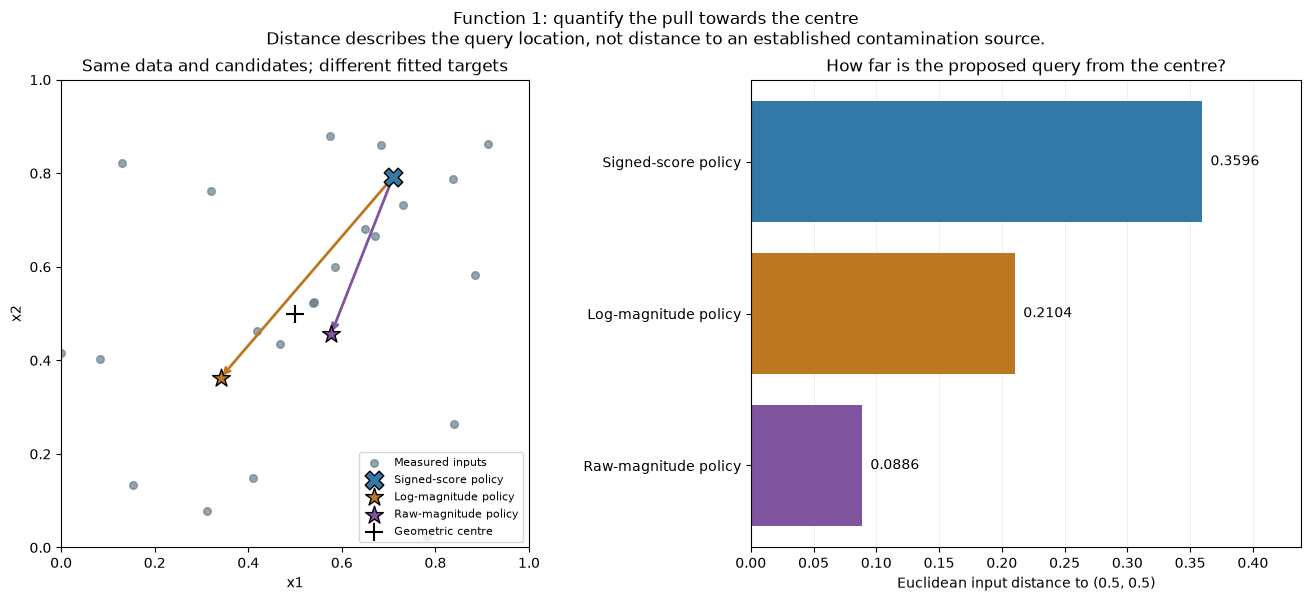

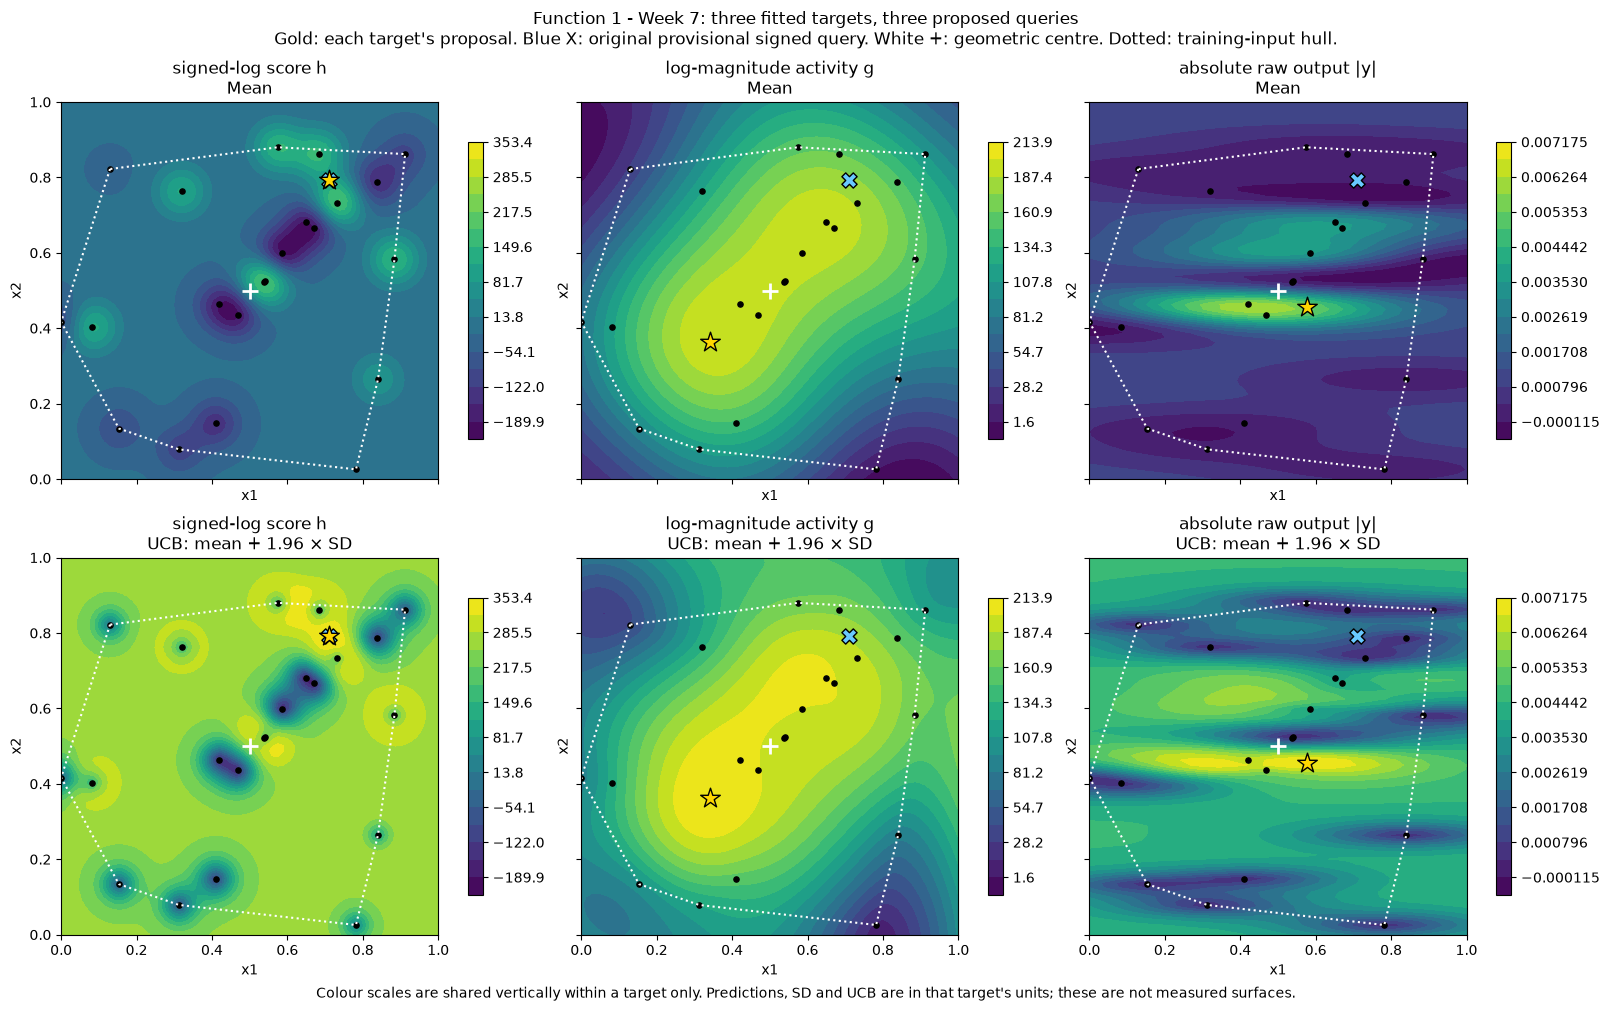

In [7]:
proposal_rows = [row for pool in policies["proposals"].values() for row in pool.values()]
display(pd.DataFrame(proposal_rows).drop(columns="point"))
display(plot_activity_query_shift(pooled, policies, input_columns=INPUT_COLUMNS, reference=reference,
    save_to=OUTPUT_DIR / "query-shift-towards-centre.png"))
decision_figure = plot_activity_decisions(study, policies, official, pooled, input_columns=INPUT_COLUMNS,
    reference=reference, weight=WEIGHT)
decision_figure.suptitle("Function 1 - Week 7: three fitted targets, three proposed queries\n"
    "Gold: each target's proposal. Blue X: original provisional signed query. White +: geometric centre. Dotted: training-input hull.")
decision_figure.savefig(OUTPUT_DIR / "target-decision-maps.png", dpi=150, bbox_inches="tight")
display(decision_figure)


## 4. Check model family, data scope and exploration weight

The same-family table changes the target while holding the GP family, training scope, candidate pool and exploration weight fixed. This distinguishes an activity effect from a different fitted model winning validation. The separate weight table uses 0, 1, 1.96 and 3; a central pull need not hold for every model or exploration preference.


In [8]:
controlled = policies["same_family_comparison"].pivot(index=["scope", "model"], columns="target", values="distance_to_centre")
controlled["Log magnitude closer than signed"] = controlled.magnitude < controlled.signed
controlled["Raw magnitude closer than signed"] = controlled.raw_magnitude < controlled.signed
display(controlled)
display(policies["weight_sensitivity"])

# Score all six candidate choices (three targets, two pools) with all selected fits.
cross_predictions, candidate_checks = [], []
known = pooled[INPUT_COLUMNS].to_numpy()
for pool_name, pool_proposals in policies["proposals"].items():
    for point_label, row in pool_proposals.items():
        point = np.asarray(row["point"])
        distances = np.linalg.norm(known - point, axis=1)
        nearest = pooled.iloc[int(np.argmin(distances))]
        assert point.shape == (2,) and ((point >= 0) & (point < 1)).all()
        np.testing.assert_array_equal(point, point.round(6))
        assert not np.any(np.all(known.round(6) == point, axis=1))
        assert all(row["portal_input"] != p.read_text().splitlines()[0] for p in SUBMISSION_PATHS)
        candidate_checks.append(dict(pool=pool_name, policy=point_label,
            portal_input=row["portal_input"], nearest_known_id=nearest.observation_id,
            nearest_known_distance=float(distances.min()),
            distance_from_latest_official=float(np.linalg.norm(point-official.loc[latest_mask, INPUT_COLUMNS].to_numpy()[0]))))
        for target_name, run in study["studies"].items():
            mean, sd = run["selected"]["model"].predict(point[None], return_std=True)
            cross_predictions.append(dict(pool=pool_name, point_policy=point_label,
                portal_input=row["portal_input"], fitted_target=target_name,
                units=TARGET_LABELS[target_name], mean=float(mean[0]), latent_sd=float(sd[0])))
display(pd.DataFrame(cross_predictions))
display(pd.DataFrame(candidate_checks))

mean_vs_ucb = policies["weight_sensitivity"].loc[lambda d: d.pool.eq("baseline") & d.weight.isin([0., WEIGHT]),
    ["target", "weight", "x1", "x2", "distance_to_centre"]]
display(mean_vs_ucb)

# Preserve last week's actual saved comparison, without recreating a historical forecast.
previous = json.loads(PREVIOUS_STUDY_PATH.read_text(encoding="utf-8"))
previous_vs_current = []
for name, row in policies["proposals"]["baseline"].items():
    before = previous["proposals"]["baseline"][name]
    previous_vs_current.append(dict(target=name, week_6_input=before["portal_input"],
        week_7_input=row["portal_input"], input_movement=float(np.linalg.norm(np.asarray(row["point"])-before["point"]))))
display(pd.DataFrame(previous_vs_current))


target                               magnitude  raw_magnitude    signed  \
scope    model                                                            
official GP: broad (l=0.35)           0.123892       0.150063  0.499736   
         GP: local (l=0.15)           0.147394       0.173808  0.498741   
         GP: separate length scales   0.181082       0.084607  0.077394   
         Gaussian process             0.190881       0.084607  0.077394   
peers    GP: broad (l=0.35)           0.131329       0.707106  0.499736   
         GP: local (l=0.15)           0.235464       0.192166  0.707105   
         GP: separate length scales   0.211352       0.088609  0.361037   
         Gaussian process             0.210433       0.115854  0.359552   

target                               Log magnitude closer than signed  \
scope    model                                                          
official GP: broad (l=0.35)                                      True   
         GP: local (l=0.15)                                      True   
         GP: separate length scales                             False   
         Gaussian process                                       False   
peers    GP: broad (l=0.35)                                      True   
         GP: local (l=0.15)                                      True   
         GP: separate length scales                              True   
         Gaussian process                                        True   

target                               Raw magnitude closer than signed  
scope    model                                                         
official GP: broad (l=0.35)                                      True  
         GP: local (l=0.15)                                      True  
         GP: separate length scales                             False  
         Gaussian process                                       False  
peers    GP: broad (l=0.35)                                     False  
         GP: local (l=0.15)                                      True  
         GP: separate length scales                              True  
         Gaussian process                                        True

,pool,target,model,scope,weight,x1,x2,distance_to_centre,reference_distance_to_centre,change_in_centre_distance,percent_closer_to_centre,movement_from_reference
0,baseline,signed,Gaussian process,official_plus_retained_peers,0.00,0.538665,0.520452,0.043741,0.359552,-0.315811,87.834594,0.320997
1,baseline,signed,Gaussian process,official_plus_retained_peers,1.00,0.725085,0.766337,0.348710,0.359552,-0.010842,3.015291,0.030251
2,baseline,signed,Gaussian process,official_plus_retained_peers,1.96,0.709459,0.792240,0.359552,0.359552,0.000000,0.000000,0.000000
3,baseline,signed,Gaussian process,official_plus_retained_peers,3.00,0.709459,0.792240,0.359552,0.359552,0.000000,0.000000,0.000000
4,baseline,magnitude,Gaussian process,official_plus_retained_peers,0.00,0.373474,0.392203,0.166220,0.359552,-0.193332,53.770240,0.522413
5,baseline,magnitude,Gaussian process,official_plus_retained_peers,1.00,0.355649,0.375073,0.190903,0.359552,-0.168648,46.905235,0.547001
6,baseline,magnitude,Gaussian process,official_plus_retained_peers,1.96,0.340635,0.362578,0.210433,0.359552,-0.149119,41.473502,0.566251
7,baseline,magnitude,Gaussian process,official_plus_retained_peers,3.00,0.332529,0.352749,0.223001,0.359552,-0.136551,37.978044,0.578989
8,baseline,raw_magnitude,GP: separate length scales,official_plus_retained_peers,0.00,0.443005,0.454529,0.072911,0.359552,-0.286640,79.721628,0.430170
9,baseline,raw_magnitude,GP: separate length scales,official_plus_retained_peers,1.00,0.506784,0.454361,0.046140,0.359552,-0.313411,87.167222,0.394004


,pool,point_policy,portal_input,fitted_target,units,mean,latent_sd
0,baseline,signed,0.709459-0.792240,signed,signed-log score h,112.643497,122.527757
1,baseline,signed,0.709459-0.792240,magnitude,log-magnitude activity g,177.782423,3.506587
2,baseline,signed,0.709459-0.792240,raw_magnitude,absolute raw output |y|,-0.000002,0.000808
3,baseline,magnitude,0.340635-0.362578,signed,signed-log score h,-19.455075,139.400392
4,baseline,magnitude,0.340635-0.362578,magnitude,log-magnitude activity g,198.536814,7.869119
5,baseline,magnitude,0.340635-0.362578,raw_magnitude,absolute raw output |y|,0.000805,0.001580
6,baseline,raw_magnitude,0.576742-0.455704,signed,signed-log score h,32.193279,134.915576
7,baseline,raw_magnitude,0.576742-0.455704,magnitude,log-magnitude activity g,180.050236,7.057253
8,baseline,raw_magnitude,0.576742-0.455704,raw_magnitude,absolute raw output |y|,0.005511,0.000893
9,symmetric,signed,0.709459-0.792240,signed,signed-log score h,112.643497,122.527757


,pool,policy,portal_input,nearest_known_id,nearest_known_distance,distance_from_latest_official
0,baseline,signed,0.709459-0.792240,initial-003,0.063043,0.319891
1,baseline,magnitude,0.340635-0.362578,peer-kosina-round-01,0.128008,0.253800
2,baseline,raw_magnitude,0.576742-0.455704,round-06,0.077003,0.077003
3,symmetric,signed,0.709459-0.792240,initial-003,0.063043,0.319891
4,symmetric,magnitude,0.340635-0.362578,peer-kosina-round-01,0.128008,0.253800
5,symmetric,raw_magnitude,0.576742-0.455704,round-06,0.077003,0.077003


,target,weight,x1,x2,distance_to_centre
0,signed,0.00,0.538665,0.520452,0.043741
2,signed,1.96,0.709459,0.792240,0.359552
4,magnitude,0.00,0.373474,0.392203,0.166220
6,magnitude,1.96,0.340635,0.362578,0.210433
8,raw_magnitude,0.00,0.443005,0.454529,0.072911
10,raw_magnitude,1.96,0.576742,0.455704,0.088609


,target,week_6_input,week_7_input,input_movement
0,signed,0.608515-0.846200,0.709459-0.792240,0.114461
1,magnitude,0.361195-0.379880,0.340635-0.362578,0.026871
2,raw_magnitude,0.590368-0.455132,0.576742-0.455704,0.013638


## 5. Interpret the evidence before choosing

A better activity prediction does not imply a better signed score. Compare improvement over each target's own baseline, sensitivity to retained peers and GP family, movement under weights 0, 1, 1.96 and 3, and signed predictions at the activity proposals. Keep the small adaptive sample and model-dependent uncertainty explicit.

The latest official return is a new numerical signed best but remains practically zero. An activity-led query can be justified as one information-seeking experiment even if its current signed forecast is negative. It cannot be described as a demonstrated positive improvement or source detection. Changing all input settings also prevents a causal single-coordinate interpretation.

Week-to-week movement includes the new observation and a changed incumbent-local candidate pool; it is not an isolated causal estimate of the observation's effect. The within-week shared pools and same-family controls are the like-for-like comparisons.


The additional median benchmark matters for raw magnitude: selected GP MAE is **0.000785537**, compared with **0.000569713** for the held-out median predictor. The raw fit's improvement against its mean baseline alone therefore overstates its predictive case. The log-magnitude GP beats both simple benchmarks. These diagnostics do not change the existing within-target GP-family/scope selection rule.

At weight 1.96, both baseline and expanded pools choose the same three points. Across weights 0–3, the log-magnitude proposals remain around `(0.33–0.37, 0.35–0.40)`. Raw magnitude instead shifts along a narrow band near `x2=0.455`. Holding GP family and scope fixed, log magnitude is closer to the geometric centre than signed output in **6/8** cases and raw magnitude in **5/8**. The previous week's **8/8** finding does not survive universally after the latest return; centre distance is not evidence of a source.

The recommendation uses the log-magnitude proposal as one activity-led experiment. All three selected fits use retained peers, so self-reporting and sparse official evidence remain limitations. The signed-score mean at this point is negative with broad uncertainty. No positive result or useful physical detection is promised, and the signed competition objective remains the ultimate measure of success.


In [9]:
# Retain the complete comparison, validation predictions, controls and provenance.
recommended = policies["proposals"]["baseline"]["magnitude"]
np.testing.assert_array_equal(recommended["point"], [.340635, .362578])
signed_check = next(row for row in cross_predictions
    if row["pool"] == "baseline" and row["point_policy"] == "magnitude" and row["fitted_target"] == "signed")
recommendation = {
    "status": "recommended_not_agreed_or_submitted", "portal_input": recommended["portal_input"],
    "point": recommended["point"], "target": "magnitude", "target_label": TARGET_LABELS["magnitude"],
    "policy": "one_activity_led_exploration_query", "pool": "baseline", "ucb_weight": WEIGHT,
    "model": recommended["model"], "training_scope": recommended["training_scope"],
    "rationale": "Use the log-magnitude proposal for one information-seeking query: it beats both simple target-specific baselines, retains its point under shared-pool expansion and stays in the same region across weights. The raw-magnitude GP loses to its median baseline; the signed policy is weak and uncertainty-led. Centre distance is not the selection criterion.",
    "signed_prediction_at_recommended_point": signed_check,
    "caveat": "The signed mean is negative and highly uncertain; no positive return, incumbent improvement, source location or meaningful detection is established. Retained peers are self-reported.",
    "original_signed_model_review_changed": False, "portal_submission_performed": False,
}
result = {
    "function": FUNCTION, "week": WEEK, "analysis": "activity_hypothesis", "study_date": STUDY_DATE,
    "official_rows": len(official), "feedback_through_round": 6,
    "retained_peer_rows": len(pooled)-len(official), "python_executable": sys.executable,
    "latest_official_point": official.loc[latest_mask, INPUT_COLUMNS].iloc[0].tolist(),
    "latest_official_output": float(official.loc[latest_mask, "y"].iloc[0]),
    "remaining_queries": remaining_queries(WEEK_DIR),
    "height_scale": HEIGHT_SCALE, "centre": list(CENTRE), "centre_is_a_source_estimate": False,
    "selection_metric": SELECTION_METRIC, "ucb_weight": WEIGHT,
    "settings": {"fixed": FIXED_SETTINGS, "adaptive": ADAPTIVE_SETTINGS,
                 "gp_names": GP_NAMES, "weights": list(WEIGHTS), "search": SEARCH_SETTINGS},
    "candidate_counts": {name: len(pool) for name, pool in pools.items()},
    "candidate_sha256": {name: hashlib.sha256(pool[INPUT_COLUMNS].to_numpy(dtype="<f8").tobytes()).hexdigest()
                         for name, pool in pools.items()},
    "reference_signed_proposal": reference.tolist(), "validation": validation_rows, "recommendation": recommendation,
    "centrality_controls": {"comparisons": len(controlled),
        "log_magnitude_closer": int(controlled["Log magnitude closer than signed"].sum()),
        "raw_magnitude_closer": int(controlled["Raw magnitude closer than signed"].sum())},
    "model_comparisons": {name: {"official": run["official"]["table"].to_dict(orient="records"),
        "peer_assisted": run["peers"]["table"].to_dict(orient="records")}
        for name, run in study["studies"].items()},
    "held_out_predictions": {name: {scope: {model: values.tolist() for model, values in run[scope]["predictions"].items()}
        for scope in ("official", "peers")} for name, run in study["studies"].items()},
    "proposals": policies["proposals"], "weight_sensitivity": policies["weight_sensitivity"].to_dict(orient="records"),
    "same_family_comparison": policies["same_family_comparison"].to_dict(orient="records"),
    "cross_predictions": cross_predictions, "candidate_checks": candidate_checks,
    "previous_vs_current": previous_vs_current, "median_baselines": median_baseline_rows,
    "positive_peer_reports": pooled.loc[pooled.observation_id.str.startswith("peer-") & pooled.y.gt(0)].to_dict(orient="records"),
    "opposite_sign_pairs": opposite_sign_pairs(pooled, input_columns=INPUT_COLUMNS).to_dict(orient="records"),
    "warnings": {name: {"official": run["official"]["warnings"], "peers": run["peers"]["warnings"]}
                 for name, run in study["studies"].items()},
    "source_sha256": source_before,
    "previous_submission_sha256": submission_before, "prepared_submission_changed": False,
    "new_course_evaluations": 0, "portal_submission_performed": False,
}
assert all(sha(root / name) == value for name, value in source_before.items())
assert all(sha(root / name) == value for name, value in submission_before.items())
(OUTPUT_DIR / "results.json").write_text(json.dumps(result, indent=2, allow_nan=False)+"\n", encoding="utf-8")
for name, table in {"validation": validation_rows, "cross-predictions": cross_predictions,
                    "candidate-checks": candidate_checks, "previous-vs-current": previous_vs_current}.items():
    pd.DataFrame(table).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
policies["weight_sensitivity"].to_csv(OUTPUT_DIR / "weight-sensitivity.csv", index=False)
policies["same_family_comparison"].to_csv(OUTPUT_DIR / "same-family-comparison.csv", index=False)
print(json.dumps({"comparison_complete": True, "proposals": policies["proposals"],
                  "recommendation": recommendation, "submission_changed": False, "remaining_queries": result["remaining_queries"]}, indent=2))


{
  "comparison_complete": true,
  "proposals": {
    "baseline": {
      "signed": {
        "target": "signed",
        "units": "signed-log score h",
        "pool": "baseline",
        "model": "Gaussian process",
        "training_scope": "official_plus_retained_peers",
        "point": [
          0.709459,
          0.79224
        ],
        "portal_input": "0.709459-0.792240",
        "predicted_target": 112.64349658750551,
        "latent_sd": 122.52775656431047,
        "ucb": 352.797899453554,
        "distance_to_centre": 0.35955151269463465,
        "reference_distance_to_centre": 0.35955151269463465,
        "change_in_centre_distance": 0.0,
        "percent_closer_to_centre": 0.0,
        "movement_from_reference": 0.0
      },
      "magnitude": {
        "target": "magnitude",
        "units": "log-magnitude activity g",
        "pool": "baseline",
        "model": "Gaussian process",
        "training_scope": "official_plus_retained_peers",
        "point": [
       

## Course lifecycle

1. **Define the goal and scope** — compare signed-score, log-magnitude and raw-magnitude policies and recommend the next Function 1 experiment without submitting it.
2. **Gather the data** — use 16 official observations through round 6 and six unchanged retained peer reports, with source hashes.
3. **Explore the data** — inspect measured sign, magnitude, opposite-sign proximity and the latest central return.
4. **Clean and preprocess the data** — validate snapshot alignment, dimensions, bounds and counts; preserve tiny values and declare the three separate targets.
5. **Select and engineer features** — retain both original coordinates; changing the fitted target does not create a source-location feature.
6. **Define the machine-learning task** — compare regression-guided signed-score maximisation with activity-led information heuristics.
7. **Partition the data** — use identical official leave-one-out targets, with peer rows in training only; no independent final test is available.
8. **Select and train candidate methods** — fit four established GP families independently for each target, retaining settings and search budgets.
9. **Evaluate and interpret the results** — compare within-target baselines, shared pools, model/scope/weight controls and signed predictions at every proposed point.
10. **Deploy and iterate** — deployment is not applicable; record an evidence-backed recommendation for discussion. Seven queries remain including Week 7, and no query is submitted.
